# v6 - Rio Bradano (HARMONIOUS): STIV sobre un video ya ortorrectificado, con trazador disperso

Mide la velocidad superficial del rio Bradano (Basilicata, Italia) a partir de un video de dron que
el dataset **HARMONIOUS** entrega **ya ortorrectificado y estabilizado**, con su escala declarada
(0.009 m/px), con el STIV de la v5. La geometria deja de ser el problema; la dificultad es el
**trazador**: el agua sale practicamente negra y lo unico que se ve son particulas brillantes
sueltas sobre un fondo sin nada. El dataset publica 7 velocidades de referencia, pero no batimetria:
**no hay caudal**.

**Los datos de entrada se leen en modo solo lectura. Todo lo que este notebook genera se escribe en
`salidas/`.** Las lineas de codigo que cambian respecto a la v5 llevan la marca `# [v6]`.

---
## Que cambia respecto a v5

| Parte | v5 (Hommerich) | v6 (Bradano) | Por que lo obliga este caso |
|---|---|---|---|
| 0-2 | `cam_config`, `solvePnP`, mapa de rectificacion | escala **dada** por el dataset; sin rectificar (`MAPA_RECT` = None) | el video ya es el plano del agua |
| 2 | seccion levantada con calados | malla de verticales del aforo (posiciones), **sin calados** | el dataset no publica batimetria |
| 3 | una linea por estacion | una **banda** de 7 lineas paralelas por estacion (`mapa_banda`), cada una normalizada y luego promediadas | una linea de 1 px casi nunca ve una particula: la coherencia no llega |
| 4 | 122 fotogramas, `LADO_BLOQUE` = 32 | el video entero, **600** fotogramas, y `LADO_BLOQUE` = **64** | con trazador disperso mas tiempo es mas particulas; el 32 venia del video corto de la v5, y con bloques pequenos cada uno ve tan pocas particulas que aparecen ceros falsos con coherencia alta |
| 4 | contraste temporal de cada estacion | ademas, el **brillo** medio de cada estacion | lo necesita el nuevo criterio de calidad |
| 4b | contraste >= 3.0 | contraste **desactivado** (0); **brillo <= 5.0** | la grava de la orilla tiene **mas** contraste que el agua negra: el criterio se invierte. Lo que separa agua y orilla aqui es el brillo |
| 4b-5 | relleno e integracion del caudal | **sin relleno y sin caudal**: perfil de velocidad (como la v4) | no hay calados |
| 7 | sin referencia | **7 velocidades de referencia** del dataset | validacion vertical a vertical |

**Lo que no cambia:** `construir_sti` (con `MAPA_RECT` = None no rectifica), `DS` = desplazamiento
por fotograma y antialias `DS/2`, `mapa_lineas`, `preparar_sti`, el tensor con diferencias centrales
y `SIGMA_DERIVADA` = 1.5, `medir_sti`, `COH_MIN_BLOQUE` = 0.50, `COH_MIN_ESTACION` = 0.70 y el modulo
`benchmark`.

---
## Parte 0 - Rutas de trabajo

El video es el de la carpeta `Stabilised` del dataset: el `Readme.txt` dice que las coordenadas en
pixeles de los datos de validacion estan referidas a su primer fotograma.

In [1]:
import os
from pathlib import Path

import benchmark  # modulo local (benchmark.py, en esta misma carpeta)


def buscar_datasets():
    """Carpeta 'datasets vision velocimetria', donde este."""
    candidatos = [Path("../../datos/externos/datasets vision velocimetria")]
    if os.environ.get("DATASETS_VELOCIMETRIA"):
        candidatos.append(Path(os.environ["DATASETS_VELOCIMETRIA"]))
    candidatos.append(Path("../../../test_pyorc-20261009T172625Z-1-001/test_pyorc/"
                           "datasets vision velocimetria"))
    for c in candidatos:
        if c.is_dir():
            return c
    raise SystemExit("No se encuentran los datasets externos: ver datos/externos/LEEME.md")


# --- Entradas (nunca se modifican) ---
DIR_DATOS = buscar_datasets() / "data" / "RiverBradano"                             # [v6]
ARCHIVO_VIDEO = DIR_DATOS / "Stabilised" / "Video" / "RiverBradano_24_fps_Stabilised.avi"  # [v6]
# [v6] De la hoja de validacion se leen en la Parte 2 SOLO las posiciones de las verticales;
# las velocidades no se abren hasta la Parte 7.
ARCHIVO_VALIDACION = DIR_DATOS / "Reference" / "Validation_Data_RiverBradano.xlsx"

# --- Salidas ---
DIR_SALIDA = Path("salidas")
# exist_ok=True evita el error si la carpeta ya existe de una ejecucion anterior.
DIR_SALIDA.mkdir(exist_ok=True)

SALIDA_CONFIG = DIR_SALIDA / "config.json"                 # configuracion congelada
SALIDA_PERFIL = DIR_SALIDA / "perfil_velocidades.csv"      # velocidad estacion por estacion
SALIDA_RESUMEN = DIR_SALIDA / "resumen.csv"                # [v6] tabla final (no hay caudal)
SALIDA_BENCHMARK = DIR_SALIDA / "benchmark_recursos.csv"   # coste de cada etapa

# Se vacian las mediciones por si el notebook se reejecuta sin reiniciar el kernel.
benchmark.reiniciar()

print("Datos de entrada:", DIR_DATOS)
print("Salidas en:      ", DIR_SALIDA)
# Se comprueba de una vez que las entradas existen, antes de procesar nada.
for entrada in (ARCHIVO_VIDEO, ARCHIVO_VALIDACION):                                  # [v6]
    print(f"  {'OK   ' if entrada.exists() else 'FALTA'} {entrada.name}")

Datos de entrada: ..\..\..\test_pyorc-20261009T172625Z-1-001\test_pyorc\datasets vision velocimetria\data\RiverBradano
Salidas en:       salidas
  OK    RiverBradano_24_fps_Stabilised.avi
  OK    Validation_Data_RiverBradano.xlsx


---
## Parte 1 - Lectura del video

1920x1080 a 24 fps, 600 fotogramas (25 s), en escala de grises y comprimido con perdida (el dataset
no publica los fotogramas sin comprimir). El agua sale casi negra: junto al fotograma se muestra una
version con el contraste estirado, sin la cual no se ve nada dentro del cauce.

Dimensiones del fotograma: (1080, 1920, 3)
FPS del video: 24.0000  ->  DT = 41.667 ms
Fotogramas en el video: 600


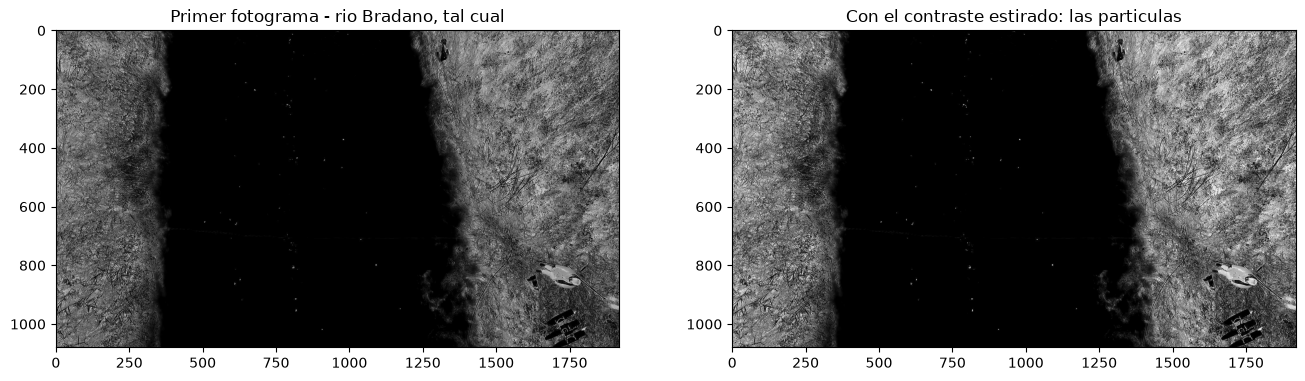

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# OpenCV: los metadatos y el primer fotograma del video que se mide.
cap = cv2.VideoCapture(str(ARCHIVO_VIDEO))
FPS = cap.get(cv2.CAP_PROP_FPS)
N_TOTAL = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
ok, frame_bgr = cap.read()
cap.release()
DT = 1.0 / FPS                    # intervalo entre fotogramas: entra en la velocidad
# OpenCV lee en BGR; matplotlib espera RGB.
frame = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
# [v6] El mismo fotograma con el contraste estirado entre percentiles.
gris0 = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
lo, hi = np.percentile(gris0, [1, 99.5])
frame_realce = np.clip((gris0 - lo) / (hi - lo) * 255, 0, 255).astype(np.uint8)

# Forma (filas, columnas, canales): las filas son la altura y las columnas el ancho.
print(f"Dimensiones del fotograma: {frame.shape}")
print(f"FPS del video: {FPS:.4f}  ->  DT = {DT * 1000:.3f} ms")
print(f"Fotogramas en el video: {N_TOTAL}")

fig, ax = plt.subplots(1, 2, figsize=(16, 5))                                       # [v6]
ax[0].imshow(frame); ax[0].set_title("Primer fotograma - rio Bradano, tal cual")
ax[1].imshow(frame_realce, cmap="gray"); ax[1].set_title("Con el contraste estirado: las particulas")
plt.savefig(DIR_SALIDA / "fig1_fotograma.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 2 - Geometria: la escala la da el dataset

El `Readme.txt` del Bradano declara **0.009 m/px** para la imagen estabilizada: el video ya es una
proyeccion sobre el plano del agua. No hay pose de camara que resolver ni mapa de rectificacion.

Conviene comprobar la escala, y el propio dataset da con que **sin mirar ninguna velocidad**: las 7
verticales de validacion estan en las columnas 456, 567, ..., 1122, separadas exactamente 111 px;
a 0.009 m/px son 0.999 m, la separacion redonda de un aforo.

La seccion es la **fila 706** y el flujo va en vertical (hacia arriba en la imagen). Las estaciones
siguen la malla de 1 m del aforo, prolongada hasta cubrir el ancho mojado: siete caen sobre
verticales de validacion y dos se anaden para llegar a la orilla derecha.

Escala declarada: 9.00 mm/px; separacion entre verticales de validacion 111 px = 0.999 m
Ancho mojado: 8.73 m; estaciones en las columnas [456, 567, 678, 789, 900, 1011, 1122, 1233, 1344]


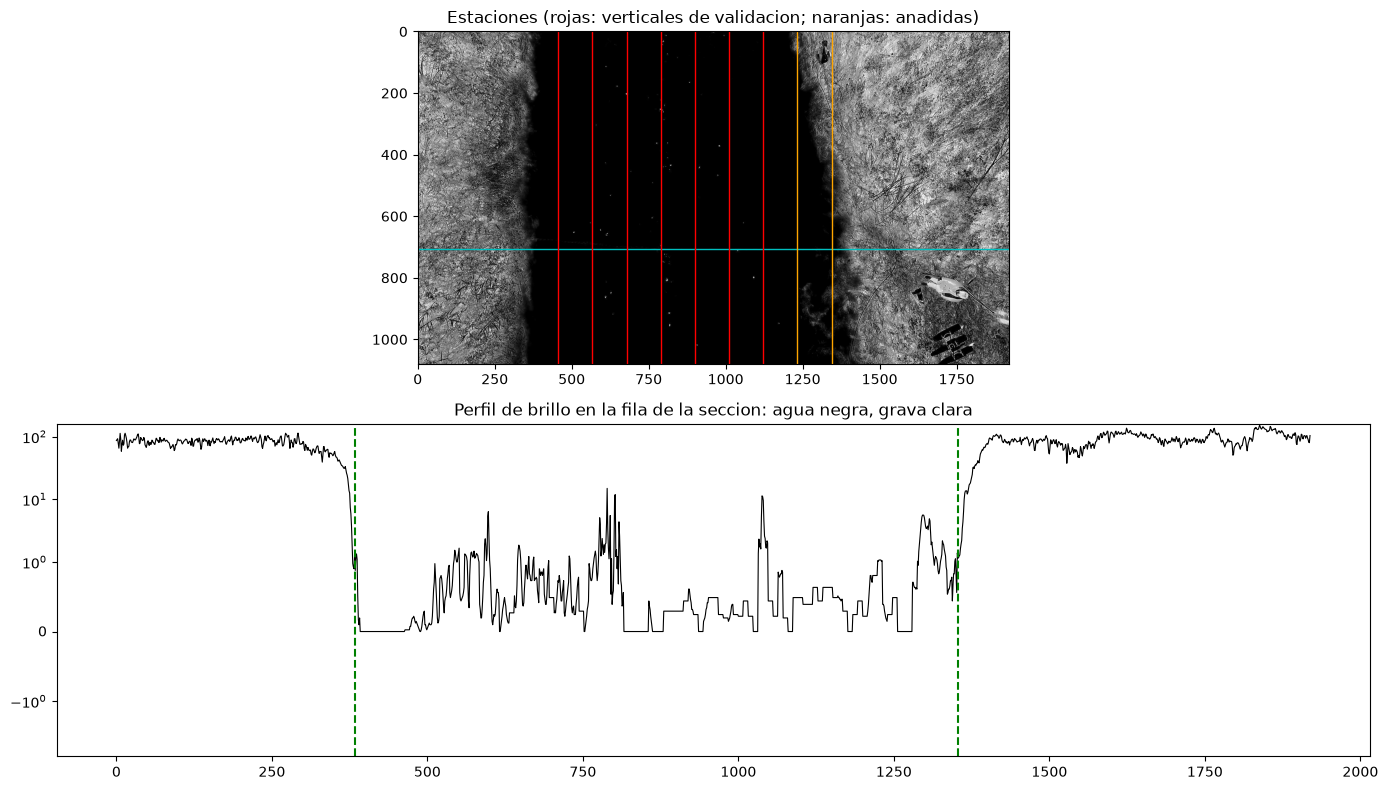

In [3]:
import pandas as pd

# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Geometria                                                       [v6]
# ---------------------------------------------------------------------------------------
# Escala de la imagen ortorrectificada, declarada por el Readme.txt.  (obtenido del dataset)
ESCALA = 0.009                # m/px
# Fila de la seccion de aforo.  (obtenido del dataset)
FILA_SECCION = 706
# Columnas donde el agua toca cada orilla en esa fila: el perfil de brillo cae de ~60 a < 1
# nivel de gris en pocos pixeles (figura de abajo). Solo situan el perfil.
COLUMNA_AGUA_IZQ, COLUMNA_AGUA_DER = 383, 1353
# Malla de estaciones: la del aforo (111 px = 1 m desde la columna 456), prolongada a la
# derecha hasta donde cabe dentro del agua.  (obtenido del dataset)
COLUMNA_ESTACION_0, PASO_ESTACION_PX, N_ESTACIONES = 456, 111, 9
# ---------------------------------------------------------------------------------------

columnas_estaciones = COLUMNA_ESTACION_0 + PASO_ESTACION_PX * np.arange(N_ESTACIONES)
s_estaciones = (columnas_estaciones - COLUMNA_AGUA_IZQ) * ESCALA
MAPA_RECT = None              # [v6] el video ya esta en el plano del agua

# Las coordenadas de las verticales de validacion: SOLO las posiciones.
_val = pd.read_excel(ARCHIVO_VALIDACION, header=None)
_fil = _val[_val[0].astype(str).str.startswith("Vert")]
COLUMNAS_VALIDACION = _fil[1].astype(int).to_numpy()
print(f"Escala declarada: {ESCALA * 1000:.2f} mm/px; separacion entre verticales de validacion "
      f"{np.diff(COLUMNAS_VALIDACION).mean():.0f} px = {np.diff(COLUMNAS_VALIDACION).mean() * ESCALA:.3f} m")
print(f"Ancho mojado: {(COLUMNA_AGUA_DER - COLUMNA_AGUA_IZQ) * ESCALA:.2f} m; "
      f"estaciones en las columnas {columnas_estaciones.tolist()}")

banda_brillo = gris0[FILA_SECCION - 20:FILA_SECCION + 21].mean(axis=0)
fig, ax = plt.subplots(2, 1, figsize=(14, 8))
ax[0].imshow(frame_realce, cmap="gray")
ax[0].axhline(FILA_SECCION, color="c", lw=1)
for c in columnas_estaciones:
    ax[0].axvline(c, color="r" if c in COLUMNAS_VALIDACION else "orange", lw=1)
ax[0].set_title("Estaciones (rojas: verticales de validacion; naranjas: anadidas)")
ax[1].plot(banda_brillo, "k-", lw=0.8)
for c in (COLUMNA_AGUA_IZQ, COLUMNA_AGUA_DER):
    ax[1].axvline(c, color="g", ls="--")
ax[1].set_yscale("symlog", linthresh=1.0)
ax[1].set_title("Perfil de brillo en la fila de la seccion: agua negra, grava clara")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig2_geometria.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 3 - Lineas de busqueda: una banda por estacion

Una columna de un pixel de ancho pasa la mayor parte de los 25 s sin ninguna particula encima, y el
tensor se queda sin textura que orientar. La solucion es muestrear una **banda** de lineas
paralelas, **normalizar la STI de cada una por separado y promediarlas**: cada linea aporta las pocas
particulas que le tocan, y como todas se normalizan antes, entran con el mismo peso. La celda de la
Parte 4 mide la coherencia con una linea y con la banda.

No es lo mismo que ensanchar el antialias: el filtro promedia *intensidades* antes de muestrear y
borra las particulas debiles; la banda promedia *STI normalizadas*.

La banda es de 24 px (0.216 m, un 22 % de la separacion entre estaciones): promedia a traves de la
seccion, que es justo la direccion en la que se quiere resolver el perfil.

Desplazamiento esperado: 4.17 px/fotograma -> DS = 4 px, sigma antialias = 2.0 px, estelas a 46.2 grados
9 estaciones x 7 lineas de 128 muestras (4.61 m cada una)


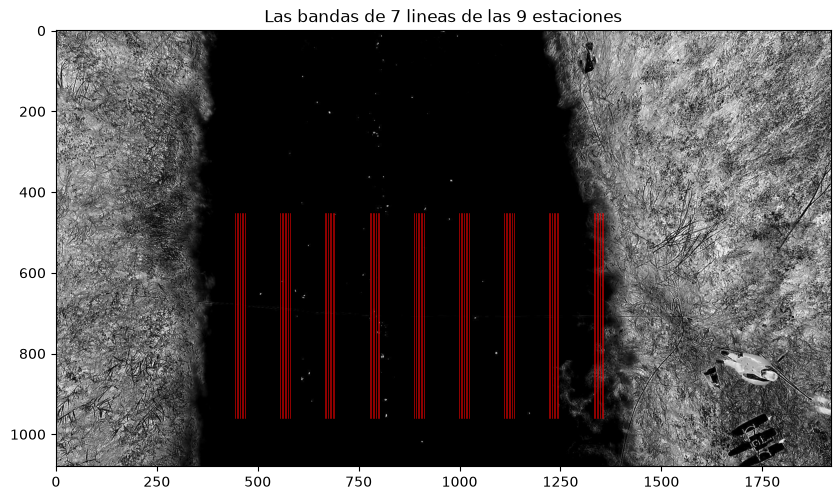

In [4]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Lineas de busqueda
# ---------------------------------------------------------------------------------------
# Direccion del flujo: hacia arriba en la imagen (la correlacion de fase entre fotogramas
# consecutivos da desviaciones de la vertical de -0.6 a -3.9 grados en la parte activa).
ANGULO_FLUJO = -90.0          # grados
# Orden de magnitud de la velocidad superficial: de aqui sale el paso de muestreo.
V_ESPERADA = 0.9              # m/s   [v6]
# [v6] Longitud de cada linea (128 muestras a DS px son ~4.6 m de rio) y banda de lineas
# paralelas: 24 px de ancho, una linea cada 4 px.
LARGO_LINEA = 128 * 4 * ESCALA   # m
ANCHO_BANDA, PASO_BANDA = 24, 4  # px
# ---------------------------------------------------------------------------------------

# [v6] Estaciones: la columna de cada vertical, en la fila de la seccion.
centros = np.column_stack([columnas_estaciones, np.full(N_ESTACIONES, FILA_SECCION)])
D_ESPERADO = V_ESPERADA * DT / ESCALA        # px por fotograma
DS = int(round(D_ESPERADO))                  # paso de muestreo: estelas a ~45 grados
SIGMA_ANTIALIAS = 0.5 * DS                   # filtro paso bajo obligatorio antes de submuestrear
print(f"Desplazamiento esperado: {D_ESPERADO:.2f} px/fotograma -> DS = {DS} px, "
      f"sigma antialias = {SIGMA_ANTIALIAS:.1f} px, estelas a "
      f"{np.degrees(np.arctan(D_ESPERADO / DS)):.1f} grados")


def mapa_lineas(centros, angulos_deg, ds, largo):
    """Coordenadas de muestreo de cada linea: mapx, mapy de forma (n_lineas, n_muestras).

    Cada linea tiene su centro (x, y) y su largo en px.
    """
    centros = np.atleast_2d(np.asarray(centros, float))
    angs = np.radians(np.broadcast_to(np.asarray(angulos_deg, float), (len(centros),)))
    n_mu = int(largo / ds)
    # t recorre la linea centrada en su punto medio, en pixeles
    t = (np.arange(n_mu) - (n_mu - 1) / 2) * ds
    mapx = np.zeros((len(centros), n_mu), np.float32)
    mapy = np.zeros((len(centros), n_mu), np.float32)
    for i, ((cx, cy), a) in enumerate(zip(centros, angs)):
        mapx[i] = cx + t * np.cos(a)
        mapy[i] = cy + t * np.sin(a)
    return mapx, mapy


def mapa_banda(centros, angulo_deg, ds, largo, ancho, paso):
    """[v6] Una banda de lineas paralelas por estacion: (n_est * n_banda, n_muestras)."""
    a = np.radians(angulo_deg)
    perp = np.array([-np.sin(a), np.cos(a)])          # a traves de la linea
    offsets = np.arange(-ancho / 2, ancho / 2 + 1e-9, paso)
    c = np.asarray(centros, float)
    todos = (c[:, None, :] + offsets[None, :, None] * perp).reshape(-1, 2)
    return (*mapa_lineas(todos, angulo_deg, ds, largo), len(offsets))


mapx, mapy, N_BANDA = mapa_banda(centros, ANGULO_FLUJO, DS, LARGO_LINEA / ESCALA,
                                 ANCHO_BANDA, PASO_BANDA)                          # [v6]
print(f"{N_ESTACIONES} estaciones x {N_BANDA} lineas de {mapx.shape[1]} muestras "
      f"({mapx.shape[1] * DS * ESCALA:.2f} m cada una)")

plt.figure(figsize=(10, 6))
plt.imshow(frame_realce, cmap="gray")                                                # [v6]
for i in range(mapx.shape[0]):
    plt.plot(mapx[i], mapy[i], "r-", lw=0.4)
plt.title(f"Las bandas de {N_BANDA} lineas de las {N_ESTACIONES} estaciones")
plt.savefig(DIR_SALIDA / "fig3_lineas_busqueda.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4 - Velocidades superficiales con STIV

El proceso de la v5, sin rectificacion (el video ya es el plano del agua) y con dos parametros que
cambian por el trazador disperso: el **video entero** (600 fotogramas, mas particulas por linea) y
**bloques de 64** (el 32 de la v5 respondia a un video de 122 fotogramas; aqui, con bloques pequenos,
muchos ven una o ninguna particula y el fondo negro y quieto da ceros falsos muy coherentes).

Antes de normalizar se guardan, por estacion, el **contraste temporal** y el **brillo medio**, que
usa la Parte 4b.

In [5]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Cuanto video se procesa y parametros del estimador
# ---------------------------------------------------------------------------------------
# [v6] El video entero: 600 fotogramas son los 25 s. Con trazador disperso, mas tiempo es
# mas particulas por linea, y el coste de memoria de STIV no crece con la duracion.
N_FRAMES = 600
# [v6] Lado del bloque de STI: vuelve a 64 (el video ya no es corto).
LADO_BLOQUE = 64
# Coherencia minima para que un bloque entre en la mediana ponderada.
COH_MIN_BLOQUE = 0.50
# Suavizado gaussiano previo a las derivadas, en pixeles de STI.
SIGMA_DERIVADA = 1.5
# ---------------------------------------------------------------------------------------


def construir_sti(archivo, mapx, mapy, n_frames, sigma, mapa_rect=None):
    """Apila n_frames filas muestreadas -> STI de forma (n_lineas, n_frames, n_muestras).

    Si se da un mapa de rectificacion (mapx, mapy del plano a la imagen), cada fotograma se
    rectifica con remap antes del antialias.
    """
    cap = cv2.VideoCapture(str(archivo))
    sti = np.zeros((mapx.shape[0], n_frames, mapx.shape[1]), np.float32)
    for k in range(n_frames):
        ok, fr = cap.read()
        if not ok:
            sti = sti[:, :k, :]
            break
        gris = cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY).astype(np.float32)
        if mapa_rect is not None:
            gris = cv2.remap(gris, mapa_rect[0], mapa_rect[1], cv2.INTER_LINEAR)
        # Antialias ANTES de muestrear: sin esto el submuestreo inventa orientaciones.
        gris = cv2.GaussianBlur(gris, (0, 0), sigma)
        sti[:, k, :] = cv2.remap(gris, mapx, mapy, cv2.INTER_LINEAR)
    cap.release()
    return sti


def preparar_sti(sti):
    """Quita el fondo estatico y el parpadeo global, y normaliza."""
    a = sti - sti.mean(axis=0, keepdims=True)   # fondo fijo de cada muestra (rayas verticales)
    a = a - a.mean(axis=1, keepdims=True)       # parpadeo de cada fotograma (rayas horizontales)
    d = a.std()
    return a / d if d > 0 else a


def tensor_estructura(bloque, sigma=SIGMA_DERIVADA):
    """Pendiente m (muestras/fotograma) y coherencia C de un trozo de STI."""
    # Gaussiana opcional y diferencias centrales.
    g = cv2.GaussianBlur(bloque, (0, 0), sigma) if sigma > 0 else bloque
    # eje 0 = tiempo (filas), eje 1 = espacio (columnas)
    It, Ix = np.gradient(g)
    Jxx = float((Ix * Ix).sum())
    Jtt = float((It * It).sum())
    Jxt = float((Ix * It).sum())
    if Jxx + Jtt <= 0:
        return np.nan, 0.0
    # autovector del autovalor MENOR = direccion a lo largo de las estelas
    _, vec = np.linalg.eigh(np.array([[Jxx, Jxt], [Jxt, Jtt]]))
    ex, et = vec[:, 0]
    if et < 0:            # el autovector esta definido salvo signo: se orienta hacia t creciente
        ex, et = -ex, -et
    m = ex / et if et != 0 else np.nan
    coherencia = np.sqrt((Jxx - Jtt) ** 2 + 4 * Jxt ** 2) / (Jxx + Jtt)
    return m, float(coherencia)


def medir_sti(sti_p, lado=LADO_BLOQUE, coh_min=COH_MIN_BLOQUE, sigma=SIGMA_DERIVADA):
    """Pendiente robusta de una STI, por bloques con solape: (m, coherencia mediana)."""
    nt, nx = sti_p.shape
    paso = lado // 2
    ms, cs = [], []
    for t0 in range(0, nt - lado + 1, paso):
        for x0 in range(0, nx - lado + 1, paso):
            m, c = tensor_estructura(sti_p[t0:t0 + lado, x0:x0 + lado], sigma)
            if np.isfinite(m):
                ms.append(m); cs.append(c)
    if not ms:
        return np.nan, 0.0
    ms, cs = np.array(ms), np.array(cs)
    coh_mediana = float(np.median(cs))
    usables = cs >= coh_min
    if usables.sum() == 0:
        return np.nan, coh_mediana
    # mediana ponderada por coherencia: los bloques nitidos pesan mas
    mm, cc = ms[usables], cs[usables]
    orden = np.argsort(mm)
    mm, cc = mm[orden], cc[orden]
    acumulado = np.cumsum(cc) / cc.sum()
    return float(mm[np.searchsorted(acumulado, 0.5)]), coh_mediana


# Unica pasada sobre el video: el bloque caro del notebook.
with benchmark.medir("Parte 4: construir las STI", n_frames=N_FRAMES):
    sti_crudo = construir_sti(ARCHIVO_VIDEO, mapx, mapy, N_FRAMES, SIGMA_ANTIALIAS,
                              MAPA_RECT)
# [v6] (estacion, linea de la banda, tiempo, muestra)
sti_crudo = sti_crudo.reshape(N_ESTACIONES, N_BANDA, *sti_crudo.shape[1:])
np.save(DIR_SALIDA / "sti_crudo.npy", sti_crudo)
# Contraste temporal y [v6] brillo medio de cada estacion, antes de normalizar.
CONTRASTE = np.median(sti_crudo.std(axis=2), axis=2).mean(axis=1)
BRILLO = sti_crudo.mean(axis=(1, 2, 3))

with benchmark.medir("Parte 4: preparar STI + tensor de estructura"):
    # [v6] Cada linea de la banda se normaliza por separado y luego se promedian.
    sti_prep = np.stack([np.mean([preparar_sti(l) for l in banda], axis=0) for banda in sti_crudo])
    v_stiv = np.full(N_ESTACIONES, np.nan)
    coherencia = np.full(N_ESTACIONES, np.nan)
    for i in range(N_ESTACIONES):
        m, coherencia[i] = medir_sti(sti_prep[i])
        v_stiv[i] = m * DS * ESCALA / DT if np.isfinite(m) else np.nan

print(f"STI: {N_ESTACIONES} estaciones x {N_BANDA} lineas x {sti_crudo.shape[2]} fotogramas x "
      f"{sti_crudo.shape[3]} muestras")
print(pd.DataFrame({"estacion": np.arange(N_ESTACIONES), "columna": columnas_estaciones,
                    "s_m": s_estaciones, "brillo": BRILLO, "contraste": CONTRASTE,
                    "coherencia": coherencia, "v_ms": v_stiv})
      .to_string(index=False, float_format=lambda x: f"{x:8.4f}"))

  [bench] Parte 4: construir las STI: 45.8 s | CPU 58.3 s (1.3 nucleos) | RAM pico 271 MB


  [bench] Parte 4: preparar STI + tensor de estructura: 0.4 s | CPU 0.4 s (0.9 nucleos) | RAM pico 240 MB
STI: 9 estaciones x 7 lineas x 600 fotogramas x 128 muestras
 estacion  columna      s_m   brillo  contraste  coherencia     v_ms
        0      456   0.6570   0.0127     0.0000      0.2405   0.0124
        1      567   1.6560   0.2320     1.7859      0.7312   1.3037
        2      678   2.6550   0.1266     1.1349      0.8585   0.9414
        3      789   3.6540   0.4228     2.8676      0.9270   0.7428
        4      900   4.6530   0.2077     1.5754      0.8851   0.6344
        5     1011   5.6520   0.1216     0.4096      0.8921   0.4790
        6     1122   6.6510   0.0286     0.0096      0.3672   0.1746
        7     1233   7.6500   0.1612     0.0000      0.3996   0.0043
        8     1344   8.6490  12.4618     2.9819      0.8038  -0.0041


Coherencia mediana por estacion:
 estacion  una linea  banda de 7
        0      0.230       0.241
        1      0.501       0.731
        2      0.783       0.859
        3      0.881       0.927
        4      0.772       0.885
        5      0.709       0.892
        6      0.390       0.367
        7      0.359       0.400
        8      0.807       0.804

Estaciones por encima de 0.70: una linea 5, banda 6


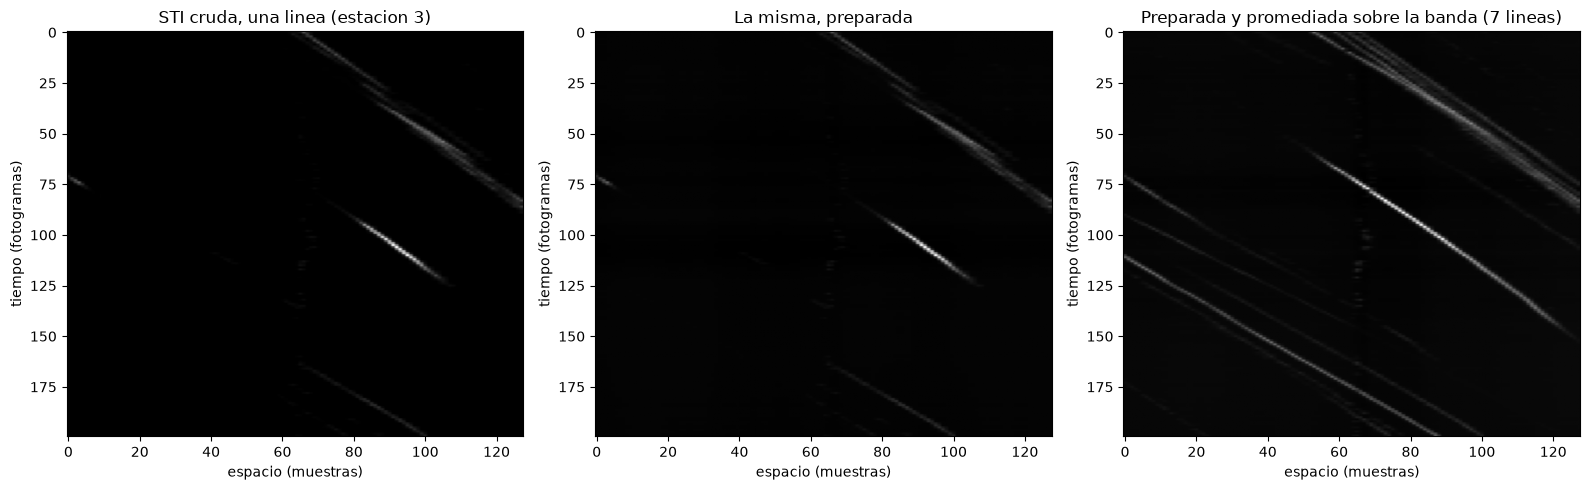

In [6]:
# [v6] Celda nueva: por que hace falta la banda. Coherencia mediana con la linea central sola
# y con la banda entera, con todo lo demas igual.
una_linea = [medir_sti(preparar_sti(banda[N_BANDA // 2]))[1] for banda in sti_crudo]
print("Coherencia mediana por estacion:")
print(pd.DataFrame({"estacion": np.arange(N_ESTACIONES), "una linea": una_linea,
                    f"banda de {N_BANDA}": coherencia})
      .to_string(index=False, float_format=lambda x: f"{x:6.3f}"))
print(f"\nEstaciones por encima de 0.70: una linea {int((np.array(una_linea) >= 0.70).sum())}, "
      f"banda {int((coherencia >= 0.70).sum())}")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
i_demo = 3
axes[0].imshow(sti_crudo[i_demo, N_BANDA // 2, :200], cmap="gray", aspect="auto")
axes[0].set_title(f"STI cruda, una linea (estacion {i_demo})")
axes[1].imshow(preparar_sti(sti_crudo[i_demo, N_BANDA // 2])[:200], cmap="gray", aspect="auto")
axes[1].set_title("La misma, preparada")
axes[2].imshow(sti_prep[i_demo][:200], cmap="gray", aspect="auto")
axes[2].set_title(f"Preparada y promediada sobre la banda ({N_BANDA} lineas)")
for ax in axes:
    ax.set_xlabel("espacio (muestras)"); ax.set_ylabel("tiempo (fotogramas)")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig4_banda.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4b - Control de calidad

La trampa del cero estatico vuelve a aparecer, con otro disfraz: la estacion de la orilla derecha
pisa la grava y da coherencia alta con velocidad cero. Pero el discriminante que lo resolvio en la v4
y la v5, el **contraste temporal**, aqui **se invierte**: la grava, clara y con ruido de compresion,
es lo que mas contraste temporal tiene de todo el fotograma, mas que el agua negra con particulas
sueltas. Con el umbral de la v5 se rechazaria todo el agua y se aceptaria la orilla.

El discriminante limpio aqui es el **brillo**: el agua del Bradano es negra (brillo medio de la STI
por debajo de 0.5 niveles de gris) y la grava no (mas de 10). `BRILLO_MAX_AGUA` = 5.0 esta en mitad
del hueco. El criterio de contraste se deja en el codigo y se desactiva para este caso.

**No se rellena**: sin calados no hay caudal que integrar (como en la v4).

In [7]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Criterios de aceptacion
# ---------------------------------------------------------------------------------------
# Coherencia mediana minima para dar por buena una estacion. La misma de la v3 a la v5.
COH_MIN_ESTACION = 0.70
# [v6] Desactivado: en este video la orilla tiene mas contraste temporal que el agua.
CONTRASTE_MIN = 0.0
# [v6] Brillo medio maximo de la STI para considerar que la estacion mira al agua.
BRILLO_MAX_AGUA = 5.0
# ---------------------------------------------------------------------------------------

with benchmark.medir("Parte 4b: control de calidad"):
    es_estatica = CONTRASTE < CONTRASTE_MIN
    es_orilla = BRILLO > BRILLO_MAX_AGUA                                               # [v6]
    medida = (~es_estatica) & (~es_orilla) & (coherencia >= COH_MIN_ESTACION) & np.isfinite(v_stiv)  # [v6]
    v_eff = np.where(medida, v_stiv, np.nan)

print(f"Estaciones medidas: {int(medida.sum())} de {N_ESTACIONES}")
for i in np.where(~medida)[0]:
    motivo = (f"brillo {BRILLO[i]:.2f} > {BRILLO_MAX_AGUA}: la banda pisa la orilla" if es_orilla[i]
              else f"coherencia {coherencia[i]:.2f} < {COH_MIN_ESTACION}")
    print(f"  estacion {i} (columna {columnas_estaciones[i]}): RECHAZADA, {motivo}")
print(f"\nContraste temporal del agua medida: {np.round(CONTRASTE[medida], 2)}; de la orilla: "
      f"{np.round(CONTRASTE[es_orilla], 2)}  <- por eso aqui no sirve")

  [bench] Parte 4b: control de calidad: 0.0 s | CPU 0.0 s (0.0 nucleos) | RAM pico 246 MB
Estaciones medidas: 5 de 9
  estacion 0 (columna 456): RECHAZADA, coherencia 0.24 < 0.7
  estacion 6 (columna 1122): RECHAZADA, coherencia 0.37 < 0.7
  estacion 7 (columna 1233): RECHAZADA, coherencia 0.40 < 0.7
  estacion 8 (columna 1344): RECHAZADA, brillo 12.46 > 5.0: la banda pisa la orilla

Contraste temporal del agua medida: [1.79 1.13 2.87 1.58 0.41]; de la orilla: [2.98]  <- por eso aqui no sirve


---
## Parte 5 - Perfil transversal de velocidad superficial

Sin calados no hay area y sin area no hay caudal. A diferencia de la v4, el dataset si da la escala:
el resultado esta en **m/s de verdad**.

  [bench] Parte 5: perfil transversal: 0.0 s | CPU 0.0 s (0.0 nucleos) | RAM pico 243 MB
Velocidad superficial mediana: 0.7428 m/s
  rango medido: 0.479 - 1.304 m/s
Estaciones medidas: 5 de 9 (sin relleno)


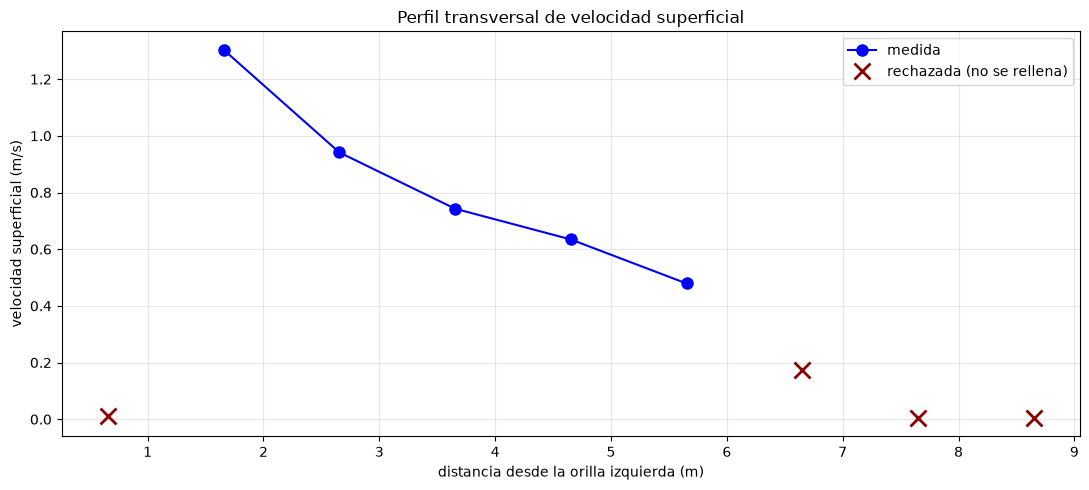

,estacion,columna_px,s_m,brillo,contraste,coherencia,v_medida_ms,estado
0,0,456,0.657,0.012726,0.000000,0.240548,NaN,coherencia baja
1,1,567,1.656,0.231972,1.785884,0.731213,1.303652,medida
2,2,678,2.655,0.126622,1.134870,0.858537,0.941368,medida
3,3,789,3.654,0.422844,2.867605,0.926955,0.742818,medida
4,4,900,4.653,0.207700,1.575367,0.885083,0.634382,medida
5,5,1011,5.652,0.121577,0.409563,0.892096,0.479032,medida
6,6,1122,6.651,0.028591,0.009578,0.367162,NaN,coherencia baja
7,7,1233,7.650,0.161178,0.000000,0.399559,NaN,coherencia baja
8,8,1344,8.649,12.461760,2.981949,0.803782,NaN,orilla (brillo)


In [8]:
with benchmark.medir("Parte 5: perfil transversal"):
    v_mediana = float(np.nanmedian(v_eff))
    v_q05, v_q95 = np.nanquantile(v_eff, [0.05, 0.95])

print("=" * 52)
print(f"Velocidad superficial mediana: {v_mediana:.4f} m/s")                       # [v6]
print(f"  rango medido: {np.nanmin(v_eff):.3f} - {np.nanmax(v_eff):.3f} m/s")
print(f"Estaciones medidas: {int(medida.sum())} de {N_ESTACIONES} (sin relleno)")
print("=" * 52)

perfil = pd.DataFrame({
    "estacion": np.arange(N_ESTACIONES),
    "columna_px": columnas_estaciones,                                                 # [v6]
    "s_m": s_estaciones,                                                               # [v6]
    "brillo": BRILLO,                                                                  # [v6]
    "contraste": CONTRASTE,
    "coherencia": coherencia,
    "v_medida_ms": v_eff,                                                              # [v6]
    "estado": np.where(medida, "medida",
                       np.where(es_orilla, "orilla (brillo)", "coherencia baja")),     # [v6]
})
perfil.to_csv(SALIDA_PERFIL, index=False)

import json
config = dict(video=ARCHIVO_VIDEO.name, n_frames=int(sti_crudo.shape[2]), fps=FPS,
              escala_m_px=ESCALA, fila_seccion=FILA_SECCION,
              columnas_estaciones=columnas_estaciones.tolist(), angulo_flujo=ANGULO_FLUJO,
              v_esperada=V_ESPERADA, ds_px=DS, sigma_antialias=SIGMA_ANTIALIAS,
              largo_linea_m=LARGO_LINEA, ancho_banda_px=ANCHO_BANDA, paso_banda_px=PASO_BANDA,
              lado_bloque=LADO_BLOQUE, coh_min_bloque=COH_MIN_BLOQUE,
              sigma_derivada=SIGMA_DERIVADA, coh_min_estacion=COH_MIN_ESTACION,
              contraste_min=CONTRASTE_MIN, brillo_max_agua=BRILLO_MAX_AGUA,
              v_mediana_ms=v_mediana)
SALIDA_CONFIG.write_text(json.dumps(config, indent=2), encoding="utf-8")

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(s_estaciones[medida], v_eff[medida], "b-o", ms=8, label="medida")
ax.plot(s_estaciones[~medida], np.abs(v_stiv[~medida]), "x", color="darkred", ms=11, mew=2,
        label="rechazada (no se rellena)")
ax.set_xlabel("distancia desde la orilla izquierda (m)")
ax.set_ylabel("velocidad superficial (m/s)")
ax.set_title("Perfil transversal de velocidad superficial")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig5_perfil.png", dpi=110, bbox_inches="tight")
plt.show()
perfil

---
## Parte 6 - Recursos consumidos

La banda multiplica por siete las muestras que hay que interpolar por fotograma, pero no el numero de
fotogramas ni de filtros, que es donde esta el tiempo: un solo `cv2.remap` resuelve las 63 lineas.

Maquina donde se han medido los tiempos:
  cpu_nucleos_fisicos: 12
  cpu_nucleos_logicos: 16
  ram_total_gb: 42.7
  ram_disponible_gb: 21.3

Tiempo total medido: 46.2 s
Pico de memoria del proceso: 271 MB


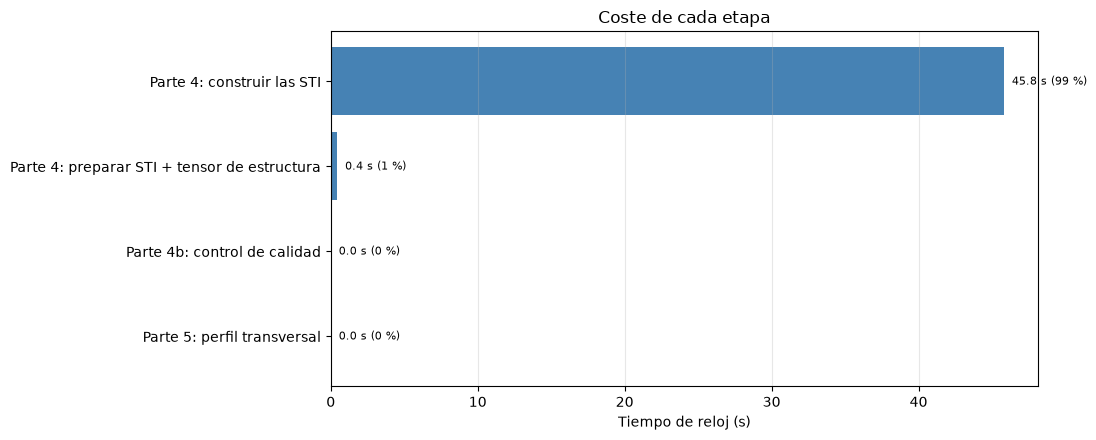

,etapa,segundos,cpu_s,nucleos,ram_pico_mb,ram_neta_mb,n_frames,pct_tiempo
0,Parte 4: construir las STI,45.81,58.34,1.27,270.7,20.3,600.0,99.1
1,Parte 4: preparar STI + tensor de estructura,0.43,0.38,0.87,239.5,2.1,NaN,0.9
2,Parte 4b: control de calidad,0.00,0.00,0.00,245.9,0.0,NaN,0.0
3,Parte 5: perfil transversal,0.00,0.00,0.00,243.0,0.0,NaN,0.0


In [9]:
print("Maquina donde se han medido los tiempos:")
for k, v in benchmark.entorno().items():
    print(f"  {k}: {v}")

tabla_recursos = benchmark.tabla()
tabla_recursos.to_csv(SALIDA_BENCHMARK, index=False)
print(f"\nTiempo total medido: {tabla_recursos['segundos'].sum():.1f} s")
print(f"Pico de memoria del proceso: {tabla_recursos['ram_pico_mb'].max():.0f} MB")

fig, ax = plt.subplots(figsize=(11, 4.5))
orden = tabla_recursos.sort_values("segundos")
ax.barh(orden["etapa"], orden["segundos"], color="steelblue")
ax.set_xlabel("Tiempo de reloj (s)")
ax.set_title("Coste de cada etapa")
ax.grid(axis="x", alpha=0.3)
for y, (seg, pct) in enumerate(zip(orden["segundos"], orden["pct_tiempo"])):
    ax.text(seg, y, f"  {seg:.1f} s ({pct:.0f} %)", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig6_recursos.png", dpi=110, bbox_inches="tight")
plt.show()
tabla_recursos

---
## Parte 7 - Comparacion con la referencia del dataset

Hasta aqui no se ha usado ni una sola velocidad de referencia: de la hoja de validacion se leyeron
en la Parte 2 solo las posiciones. La columna de velocidades se abre ahora, por primera vez.

**Esta es la ultima parte del notebook. No se vuelve atras a ajustar nada.**

vertical  estacion      s_m   v_stiv    v_ref          estado  dif_pct
   Vert1         0    0.657      NaN    0.840 coherencia baja      NaN
   Vert2         1    1.656    1.304    1.480          medida  -11.915
   Vert3         2    2.655    0.941    1.040          medida   -9.484
   Vert4         3    3.654    0.743    0.770          medida   -3.530
   Vert5         4    4.653    0.634    0.530          medida   19.695
   Vert6         5    5.652    0.479    0.430          medida   11.403
   Vert7         6    6.651      NaN    0.630 coherencia baja      NaN

Sobre las 5 verticales que STIV midio (de 7 publicadas):
  Sesgo medio : -0.0297 m/s (-3.5 %)
  RMSE        : 0.1048 m/s
  Correlacion : +0.994


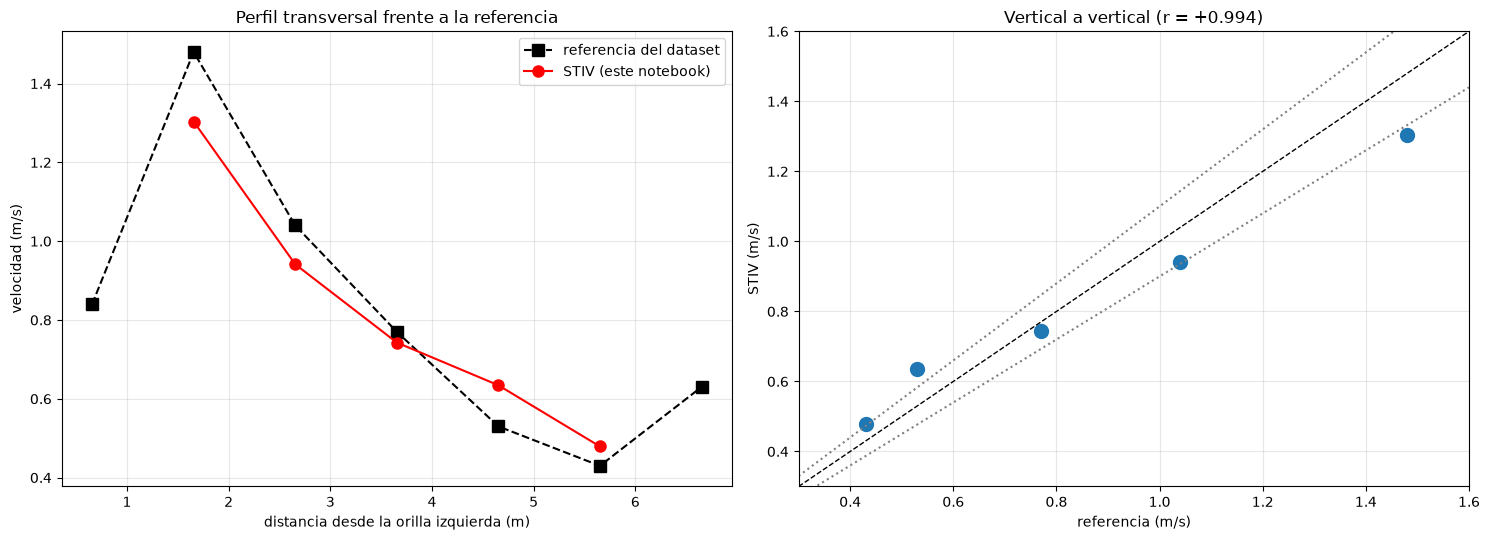

,concepto,valor,unidad
0,Velocidad superficial mediana (STIV),0.742818,m/s
1,Verticales de validacion medidas,5.000000,de 7
2,Sesgo medio relativo,-3.499957,%
3,RMSE,0.104752,m/s
4,Correlacion r,0.994444,-
5,Caudal,NaN,no calculable: el dataset no da batimetria


In [10]:
# [v6] Parte nueva.
# ---------------------------------------------------------------------------------------
#  Datos de validacion. Primera y unica vez que aparecen. (obtenido del dataset)
# ---------------------------------------------------------------------------------------
V_REFERENCIA = _fil[3].astype(float).to_numpy()   # m/s, una por vertical Vert1..Vert7
# ---------------------------------------------------------------------------------------

indice = {c: i for i, c in enumerate(columnas_estaciones)}
comparacion = pd.DataFrame([
    dict(vertical=f"Vert{k + 1}", estacion=indice[c], s_m=s_estaciones[indice[c]],
         v_stiv=v_eff[indice[c]], v_ref=vref, estado=perfil.estado[indice[c]])
    for k, (c, vref) in enumerate(zip(COLUMNAS_VALIDACION, V_REFERENCIA))])
comparacion["dif_pct"] = 100 * (comparacion.v_stiv / comparacion.v_ref - 1)
print(comparacion.to_string(index=False, float_format=lambda x: f"{x:8.3f}"))

emp = comparacion.dropna(subset=["v_stiv"])
sesgo = float((emp.v_stiv - emp.v_ref).mean())
rmse = float(np.sqrt(((emp.v_stiv - emp.v_ref) ** 2).mean()))
r = float(np.corrcoef(emp.v_stiv, emp.v_ref)[0, 1])
print("\n" + "=" * 66)
print(f"Sobre las {len(emp)} verticales que STIV midio (de {len(comparacion)} publicadas):")
print(f"  Sesgo medio : {sesgo:+.4f} m/s ({100 * sesgo / emp.v_ref.mean():+.1f} %)")
print(f"  RMSE        : {rmse:.4f} m/s")
print(f"  Correlacion : {r:+.3f}")
print("=" * 66)

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
ax[0].plot(comparacion.s_m, comparacion.v_ref, "ks--", ms=8, label="referencia del dataset")
ax[0].plot(emp.s_m, emp.v_stiv, "r-o", ms=8, label="STIV (este notebook)")
ax[0].set_xlabel("distancia desde la orilla izquierda (m)"); ax[0].set_ylabel("velocidad (m/s)")
ax[0].set_title("Perfil transversal frente a la referencia"); ax[0].grid(alpha=0.3); ax[0].legend()
lim = [0.3, 1.6]
ax[1].plot(emp.v_ref, emp.v_stiv, "o", ms=10)
ax[1].plot(lim, lim, "k--", lw=1)
ax[1].plot(lim, [1.1 * x for x in lim], ":", color="gray"); ax[1].plot(lim, [0.9 * x for x in lim], ":", color="gray")
ax[1].set_xlim(lim); ax[1].set_ylim(lim)
ax[1].set_xlabel("referencia (m/s)"); ax[1].set_ylabel("STIV (m/s)")
ax[1].set_title(f"Vertical a vertical (r = {r:+.3f})"); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig7_comparacion.png", dpi=110, bbox_inches="tight")
plt.show()

resumen = pd.DataFrame([
    dict(concepto="Velocidad superficial mediana (STIV)", valor=v_mediana, unidad="m/s"),
    dict(concepto="Verticales de validacion medidas", valor=len(emp), unidad="de 7"),
    dict(concepto="Sesgo medio relativo", valor=100 * sesgo / emp.v_ref.mean(), unidad="%"),
    dict(concepto="RMSE", valor=rmse, unidad="m/s"),
    dict(concepto="Correlacion r", valor=r, unidad="-"),
    dict(concepto="Caudal", valor=np.nan, unidad="no calculable: el dataset no da batimetria"),
])
resumen.to_csv(SALIDA_RESUMEN, index=False)
resumen

---
## Archivos generados

Todo queda en `salidas/`, sin tocar los datos de entrada.

In [11]:
print(f"Contenido de {DIR_SALIDA}:\n")
for archivo in sorted(DIR_SALIDA.iterdir()):
    # st_size da el tamano en bytes; se divide entre 1024 para mostrarlo en KiB.
    print(f"  {archivo.name:<34} {archivo.stat().st_size / 1024:>10.1f} KiB")

Contenido de salidas:

  benchmark_recursos.csv                    0.3 KiB
  config.json                               0.6 KiB
  fig1_fotograma.png                      327.6 KiB
  fig2_geometria.png                      262.8 KiB
  fig3_lineas_busqueda.png                320.7 KiB
  fig4_banda.png                          163.8 KiB
  fig5_perfil.png                          36.4 KiB
  fig6_recursos.png                        24.8 KiB
  fig7_comparacion.png                     87.4 KiB
  perfil_velocidades.csv                    0.8 KiB
  resumen.csv                               0.3 KiB
  sti_crudo.npy                         18900.1 KiB


---
## Lectura del resultado

**Lo que aporta esta version al codigo.** La **banda** de lineas normalizadas y promediadas, que es
lo que hace medible un trazador disperso, y un control de calidad en el que cada criterio se puede
desactivar o sustituir por caso: el **contraste** discrimina muros quietos (v4, v5) pero se invierte
con agua oscura; el **brillo** discrimina aqui. La trampa del cero estatico es la misma; el sintoma
que la delata cambia con la escena.

## Limitaciones conocidas

1. **No hay caudal**: el dataset no publica batimetria.
2. **Las estaciones junto a las orillas no se miden**: en sombra del talud y sin particulas, aunque la
   referencia dice que ahi hay agua corriendo. Falla la visibilidad del trazador, no la fisica.
3. **Video comprimido con perdida**: el ruido de bloque entra en los gradientes del tensor.
4. **La direccion del flujo se impone** (vertical de la imagen); la real se desvia hasta 4 grados en la
   parte activa (un 0.2 % en el modulo).
5. **La escala se toma del `Readme.txt`**; la separacion de las verticales es consistente con ella,
   pero no la verifica de forma independiente.
6. **La banda promedia 0.216 m a traves de la seccion**: suaviza el perfil donde es mas curvo.